BASE: https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data:
O dataset Breast Cancer Wisconsin (Diagnostic) é um conjunto de dados médico- computacional composto por 30 atributos quantitativos extraídos de imagens digitalizadas de biópsia por aspiração com agulha fina (FNA) de massas mamárias, destinado a modelos de classificação binária supervisada para a diferenciação de lesões benignas e malignas.

In [170]:

# importação de bibliotecas e funções
import os                                                                       # Importa a biblioteca os para manipulação de caminhos e interação com o sistema de ficheiros
import pandas as pd                                                             # Importa a biblioteca pandas para manipulação, limpeza e análise de dados tabulares (DataFrames)
import matplotlib.pyplot as plt                                                 # Importa o módulo pyplot do matplotlib para criação de gráficos e visualizações estáticas
import seaborn as sns                                                           # Importa a biblioteca seaborn para visualização estatística avançada baseada no matplotlib
import numpy as np                                                              # Importa a biblioteca numpy para computação científica e operações eficientes com matrizes numéricas

from sklearn.model_selection import train_test_split                            # Importa a função para repartir conjuntos de dados em subconjuntos de treino e teste
from sklearn.neighbors import KNeighborsClassifier                              # Importa o algoritmo de aprendizagem supervisionada K-Nearest Neighbors (KNN) para classificação
from sklearn.tree import DecisionTreeClassifier, plot_tree                      # Importa o classificador baseado em Árvore de Decisão e a ferramenta para desenhar a estrutura da árvore
from sklearn.ensemble import RandomForestClassifier                             # Importa o classificador de ensemble Random Forest (Floresta Aleatória)
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay              # Importa métricas de avaliação de modelos: pontuação de acurácia e gerador da matriz de confusão
from sklearn.metrics import recall_score                                        # # Importa a função que calcula o Recall (sensibilidade) da biblioteca scikit-learn

# 1. Carregamento Automático dos Dados
if os.path.exists('/kaggle/input/breast-cancer-wisconsin-data/data.csv'):       # Verifica se o script está a correr no Kaggle e se o ficheiro existe no caminho padrão
    df = pd.read_csv('/kaggle/input/breast-cancer-wisconsin-data/data.csv')     # Carrega o CSV do ambiente do Kaggle diretamente para um DataFrame do Pandas
elif os.path.exists('data.csv'):                                                # Verifica se o ficheiro CSV está presente no diretório de trabalho local atual
    df = pd.read_csv('data.csv')                                                # Carrega o ficheiro CSV local para o DataFrame do Pandas
else:                                                                           # Caso o ficheiro não seja encontrado em nenhum dos caminhos anteriores
    try:                                                                        # Inicia um bloco de tentativa para tentar descarregar programaticamente via Kaggle Hub
        import kagglehub                                                        # Importa dinamicamente a biblioteca oficial do Kaggle Hub
        path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data") # Descarrega o dataset atualizado do Kaggle para o ambiente
        df = pd.read_csv(f"{path}/data.csv")                                    # Carrega o ficheiro CSV descarregado a partir do caminho retornado pelo hub
    except Exception:                                                           # Captura qualquer exceção caso o download falhe (ex: ambiente Google Colab sem token)
        from google.colab import files                                          # Importa o módulo de upload interativo específico do Google Colab
        print("Por favor, faça o ficheiro data.csv:")                           # Imprime uma mensagem a instruir o utilizador a carregar o ficheiro manualmente
        uploaded = files.upload()                                               # Aciona a interface gráfica do Colab para o utilizador enviar o ficheiro
        file_name = list(uploaded.keys()[0])                                    # Extrai dinamicamente o nome do ficheiro que acabou de ser carregado
        df = pd.read_csv(file_name)                                             # Lê o ficheiro carregado pelo utilizador e armazena-o no DataFrame

# 2. Exibir a tabela original
print(f"Total de linhas (tabela original): {df.shape[0]}")                     # Imprime no console o número total de linhas do DataFrame obtido através do índice 0 da propriedade .shape
print(f"Total de colunas (tabela original): {df.shape[1]}")                    # Imprime no console o número total de colunas (incluindo o 'id' e a 'Unnamed: 32') obtido através do índice 1 da propriedade .shape
pd.set_option('display.max_columns', None)                                      # Altera a configuração global do Pandas para desativar o limite de colunas visíveis, garantindo que todas as colunas sejam mostradas sem truncagem (...)
print("\nPrimeiras 11 linhas do dataset (com 'id' e 'Unnamed: 32' ainda presentes):")   # Imprime um título explicativo precedido por uma quebra de linha (\n)
display(df.head(11))                                                            # Exibe de forma interativa (no Jupyter/Colab) as primeiras 11 linhas do DataFrame contendo os dados brutos originais


Total de linhas (tabela original): 569
Total de colunas (tabela original): 33

Primeiras 11 linhas do dataset (com 'id' e 'Unnamed: 32' ainda presentes):


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.049040,0.05373,0.015870,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.26540,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.013080,0.01860,0.013400,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.18600,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.040060,0.03832,0.020580,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.24300,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.074580,0.05661,0.018670,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.25750,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.024610,0.05688,0.018850,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.16250,0.2364,0.07678,NaN
5,843786,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,0.2087,0.07613,0.3345,0.8902,2.217,27.19,0.007510,0.033450,0.03672,0.011370,0.02165,0.005082,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.17410,0.3985,0.12440,NaN
6,844359,M,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,0.05742,0.4467,0.7732,3.180,53.91,0.004314,0.013820,0.02254,0.010390,0.01369,0.002179,22.88,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.19320,0.3063,0.08368,NaN
7,84458202,M,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,0.07451,0.5835,1.3770,3.856,50.96,0.008805,0.030290,0.02488,0.014480,0.01486,0.005412,17.06,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.15560,0.3196,0.11510,NaN
8,844981,M,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,0.07389,0.3063,1.0020,2.406,24.32,0.005731,0.035020,0.03553,0.012260,0.02143,0.003749,15.49,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.20600,0.4378,0.10720,NaN
9,84501001,M,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,0.2030,0.08243,0.2976,1.5990,2.039,23.94,0.007149,0.072170,0.07743,0.014320,0.01789,0.010080,15.09,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.22100,0.4366,0.20750,NaN


In [171]:
# 3. Limpeza do Dataset (remove o identificador e a coluna nula 'Unnamed: 32')
if 'Unnamed: 32' in df.columns:                                                 # Verifica se a coluna vazia ou com valores nulos 'Unnamed: 32' (artefato comum de exportação do CSV) existe
    df = df.drop(columns=['Unnamed: 32'])                                       # Remove permanentemente a coluna 'Unnamed: 32' do DataFrame
if 'id' in df.columns:                                                          # Verifica se a coluna de identificação única 'id' está presente no DataFrame
    df = df.drop(columns=['id'])                                                # Remove a coluna 'id' pois identificadores unívocos não contêm padrões preditivos úteis para o modelo

# 4. Exibir a tabela ajustada (pós-limpeza)
print(f"Total de linhas (após limpeza): {df.shape[0]}")                         # Imprime o número total de linhas que permanece inalterado (569)
print(f"Total de colunas (após limpeza): {df.shape[1]}")                        # Imprime o novo total de colunas após remover 'id' e 'Unnamed: 32' (passa de 33 para 31 colunas)
print("\nPrimeiras 11 linhas do dataset limpo (sem 'id' e sem 'Unnamed: 32'):") # Imprime um título explicativo para a visualização a seguir
display(df.head(11))                                                            # Exibe as primeiras 11 linhas do DataFrame limpo, contendo apenas o 'diagnosis' e as 30 features numéricas

# 5. Separação de Features (X) e Target (Y)
X = df.drop(columns=['diagnosis'])                                              # Cria a matriz de características (features/variáveis independentes) removendo a coluna alvo
Y = df['diagnosis']                                                             # Extrai a série correspondente à variável alvo (target/rótulo 'M' para maligno ou 'B' para benigno)
# As Features (X) correspondem às variáveis independentes de entrada utilizadas
# para a predição, enquanto o Target (Y) é a variável dependente de saída
# (o rótulo) que o modelo pretende prever.

# 6. Divisão dos dados em Treino e Teste (80% treino, 20% teste)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
# OBS.: O train_test_split divide aleatoriamente os dados em conjuntos de treino
# e teste, enquanto o random_state congela essa separação para garantir que esta
# seja sempre exatamente igual ao repetir o código.


Total de linhas (após limpeza): 569
Total de colunas (após limpeza): 31

Primeiras 11 linhas do dataset limpo (sem 'id' e sem 'Unnamed: 32'):


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.049040,0.05373,0.015870,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.26540,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.013080,0.01860,0.013400,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.18600,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.040060,0.03832,0.020580,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.24300,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.074580,0.05661,0.018670,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.25750,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.024610,0.05688,0.018850,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.16250,0.2364,0.07678
5,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,0.2087,0.07613,0.3345,0.8902,2.217,27.19,0.007510,0.033450,0.03672,0.011370,0.02165,0.005082,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.17410,0.3985,0.12440
6,M,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,0.05742,0.4467,0.7732,3.180,53.91,0.004314,0.013820,0.02254,0.010390,0.01369,0.002179,22.88,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.19320,0.3063,0.08368
7,M,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,0.07451,0.5835,1.3770,3.856,50.96,0.008805,0.030290,0.02488,0.014480,0.01486,0.005412,17.06,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.15560,0.3196,0.11510
8,M,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,0.07389,0.3063,1.0020,2.406,24.32,0.005731,0.035020,0.03553,0.012260,0.02143,0.003749,15.49,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.20600,0.4378,0.10720
9,M,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,0.2030,0.08243,0.2976,1.5990,2.039,23.94,0.007149,0.072170,0.07743,0.014320,0.01789,0.010080,15.09,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.22100,0.4366,0.20750


In [172]:
# 7. Dicionário contendo a descrição técnica oficial de cada uma das 31 colunas
dicionario_colunas = {
    "Coluna": [
        "diagnosis",
        "radius_mean", "texture_mean", "perimeter_mean", "area_mean", "smoothness_mean",
        "compactness_mean", "concavity_mean", "concave points_mean", "symmetry_mean", "fractal_dimension_mean",
        "radius_se", "texture_se", "perimeter_se", "area_se", "smoothness_se",
        "compactness_se", "concavity_se", "concave points_se", "symmetry_se", "fractal_dimension_se",
        "radius_worst", "texture_worst", "perimeter_worst", "area_worst", "smoothness_worst",
        "compactness_worst", "concavity_worst", "concave points_worst", "symmetry_worst", "fractal_dimension_worst"
    ],
    "Significado Técnico (Radiomics / FNA)": [
        "Variável alvo (Target): Diagnóstico clínico da lesão ('M' = Maligno, 'B' = Benigno)",
        "Média das distâncias do centro aos pontos do perímetro do núcleo celular",
        "Desvio padrão dos valores de escala de cinza (variação de brilho/textura)",
        "Média do perímetro do núcleo celular",
        "Média da área da superfície do núcleo celular",
        "Média da suavidade (variação local nos comprimentos dos raios)",
        "Média da compacidade (calculada como perímetro² / área - 1.0)",
        "Média da concavidade (severidade das porções côncavas do contorno)",
        "Média do número de pontos côncavos no contorno celular",
        "Média da simetria estrutural do núcleo celular",
        "Média da dimensão fractal (aproximação geométrica da 'linha de costa' - 1)",
        "Erro padrão (Standard Error) do raio celular",
        "Erro padrão da textura",
        "Erro padrão do perímetro",
        "Erro padrão da área",
        "Erro padrão da suavidade",
        "Erro padrão da compacidade",
        "Erro padrão da concavidade",
        "Erro padrão dos pontos côncavos",
        "Erro padrão da simetria",
        "Erro padrão da dimensão fractal",
        "Pior (maior) valor médio do raio (média dos 3 maiores valores encontrados)",
        "Pior (maior) valor da textura",
        "Pior (maior) valor do perímetro",
        "Pior (maior) valor da área",
        "Pior (maior) valor da suavidade",
        "Pior (maior) valor da compacidade",
        "Pior (maior) valor da concavidade",
        "Pior (maior) valor dos pontos côncavos",
        "Pior (maior) valor da simetria",
        "Pior (maior) valor da dimensão fractal"
    ]
}

# Converte o dicionário num DataFrame do Pandas
df_dicionario = pd.DataFrame(dicionario_colunas)

# Configura o Pandas para exibir o texto completo sem cortes
pd.set_option('display.max_colwidth', None)

# Exibe a tabela formatada no console/notebook
print("=== DICIONÁRIO TÉCNICO DAS 31 COLUNAS ===")
display(df_dicionario)


=== DICIONÁRIO TÉCNICO DAS 31 COLUNAS ===


,Coluna,Significado Técnico (Radiomics / FNA)
0,diagnosis,"Variável alvo (Target): Diagnóstico clínico da lesão ('M' = Maligno, 'B' = Benigno)"
1,radius_mean,Média das distâncias do centro aos pontos do perímetro do núcleo celular
2,texture_mean,Desvio padrão dos valores de escala de cinza (variação de brilho/textura)
3,perimeter_mean,Média do perímetro do núcleo celular
4,area_mean,Média da área da superfície do núcleo celular
5,smoothness_mean,Média da suavidade (variação local nos comprimentos dos raios)
6,compactness_mean,Média da compacidade (calculada como perímetro² / área - 1.0)
7,concavity_mean,Média da concavidade (severidade das porções côncavas do contorno)
8,concave points_mean,Média do número de pontos côncavos no contorno celular
9,symmetry_mean,Média da simetria estrutural do núcleo celular


Totais Reais no Teste:
diagnosis
B    71
M    43

Totais Previstos pelo KNN:
B    76
M    38

Recall (Sensibilidade para Malignos): 88.37%


Acurácia KNN: 95.61%




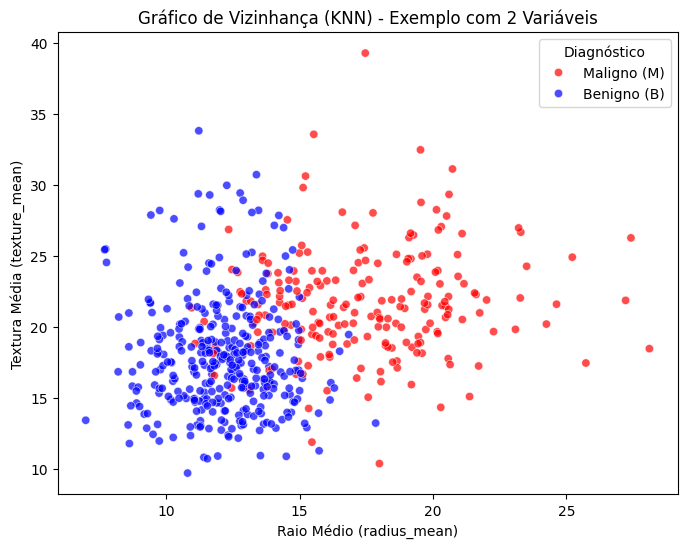

In [173]:
# ======================================================
# 8. K-Nearest Neighbors KNN (K-Vizinhos Mais Próximos)
# ======================================================

# KNN
knn = KNeighborsClassifier(n_neighbors=5)                                       # Inicializa o classificador KNN configurado para analisar os 5 vizinhos mais próximos
knn.fit(X_train, Y_train)                                                       # Treina o modelo de Machine Learning utilizando os dados de treino (características e rótulos)
knn_pred = knn.predict(X_test)                                                  # Gera previsões para o conjunto de teste (X_test) com base no conhecimento adquirido

# Conta os totais reais no conjunto de teste (Y_test)
reais = pd.Series(Y_test).value_counts()                                        # Transforma o array de testes reais numa Série e conta quantas vezes cada classe (B ou M) aparece
print("Totais Reais no Teste:")                                                 # Imprime um título no terminal para organizar a leitura
print(reais.to_string())                                                        # Mostra na tela o resultado da contagem real (quantos benignos e malignos existiam de facto)

# Conta os totais previstos pelo modelo (knn_pred)
previstos = pd.Series(knn_pred).value_counts()                                  # Transforma as previsões do modelo numa Série e conta quantas classes (B ou M) o modelo previu
print("\nTotais Previstos pelo KNN:")                                           # Imprime um título para as previsões
print(previstos.to_string())                                                                # Mostra na tela o resultado da contagem prevista pelo modelo

# Calcula o Recall especificamente para a classe 'M' (Maligno)
recall_maligno = recall_score(Y_test, knn_pred, pos_label='M')                  # Calcula a percentagem de cancros malignos reais que foram detetados com sucesso
print(f"\nRecall (Sensibilidade para Malignos): {recall_maligno:.2%}")          # Exibe o valor final do Recall formatado em percentagem
print("\n")
# O Recall (sensibilidade) mede a percentagem de casos positivos reais (como os
# tumores malignos) que o modelo conseguiu detetar com sucesso.


print(f"Acurácia KNN: {accuracy_score(Y_test, knn_pred):.2%}")                  # Calcula e imprime a percentagem de acerto do modelo comparando previsões com os rótulos reais, formatado com 4 casas decimais
print("\n")

# Gráfico: Dispersão com 2 features principais, usando duas colunas
# representativas para o gráfico 2D: 'radius_mean' e 'texture_mean'
plt.figure(figsize=(8, 6))                                                      # Cria uma nova figura para o gráfico com dimensões de 8x6 polegadas
sns.scatterplot(                                                                # Cria um gráfico de dispersão (scatterplot) usando a biblioteca Seaborn
    data=df,                                                                    # Define o DataFrame de origem dos dados
    x='radius_mean',                                                            # Atribui a coluna 'radius_mean' ao eixo X (horizontal)
    y='texture_mean',                                                           # Atribui a coluna 'texture_mean' ao eixo Y (vertical)
    hue='diagnosis',                                                            # Separa e colore os pontos com base na coluna de diagnóstico ('M' ou 'B')
    palette={'M': 'red', 'B': 'blue'},                                          # Define manualmente as cores: vermelho para Maligno ('M') e azul para Benigno ('B')
    alpha=0.7                                                                   # Define a transparência dos pontos para facilitar a visualização de sobreposições
)
plt.title("Gráfico de Vizinhança (KNN) - Exemplo com 2 Variáveis")              # Adiciona o título principal ao gráfico
plt.xlabel("Raio Médio (radius_mean)")                                          # Define o rótulo descritivo do eixo X
plt.ylabel("Textura Média (texture_mean)")                                      # Define o rótulo descritivo do eixo Y
handles, labels = plt.gca().get_legend_handles_labels()                         # Captura os elementos e rótulos criados automaticamente pelo Seaborn e ajusta a ordem/nomes
plt.legend(handles=handles, labels=['Maligno (M)', 'Benigno (B)'], title="Diagnóstico")   # O Seaborn organiza por ordem alfabética ('M' e depois 'B')
plt.show()                                                                      # Renderiza e exibe o gráfico no ecrã


Este gráfico facilita a compreensão do KNN ao mostrar que os tumores benignos (azuis) se concentram à esquerda por apresentarem um raio menor e textura regular, enquanto os malignos (vermelhos) se espalham à direita devido ao maior tamanho e textura irregular; na prática, o algoritmo decide o diagnóstico de um novo ponto avaliando a "cor" (classe) predominante dos seus vizinhos mais próximos nesta vizinhança visual.

In [174]:
# =======================
# Entrada Interativa KNN
# =======================

print("\n--- Insira os dados do novo paciente ---")                             # Imprime o cabeçalho estético no terminal
print("Dica: Cole todos os 30 valores separados por vírgula de uma só vez.")    # Mostra a instrução de uso para o utilizador

# Recebe todos os valores numa única linha no terminal
entrada_usuario = input("Informe os 30 valores separados por vírgula:\n> ")     # Aguarda a digitação/colagem da linha com os 30 valores

# Transforma a string colada numa lista de números (float)
valores_lista = [float(valor.strip()) for valor in entrada_usuario.split(',')]  # Divide o texto por vírgulas, limpa espaços e converte para número decimal

# Converte num DataFrame utilizando as mesmas colunas do treino (X.columns)
df_novo_paciente = pd.DataFrame([valores_lista], columns=X.columns)             # Cria um DataFrame do Pandas alinhado com as colunas originais do modelo
print('\n----------------------------------------')

# Realiza a predição utilizando o DataFrame estruturado
classeRetornada = knn.predict(df_novo_paciente)                                 # Passa os dados estruturados para o KNN prever o diagnóstico
print(f"Classe Retornada: {classeRetornada}")                                   # Imprime no terminal a classe bruta devolvida pelo modelo
if classeRetornada[0] == 'B':                                                   # Condicional: se o resultado for 'B' (Benigno)
    print('Resultado: O paciente apresenta tumor BENIGNO (B).')                 # Mostra mensagem indicando tumor benigno
else:                                                                           # Caso contrário (se for 'M')
    print('Resultado: O paciente apresenta tumor MALIGNO (M).')                 # Mostra mensagem indicando tumor maligno
print('----------------------------------------')                               # Imprime a linha de fecho da caixa de resultados



--- Insira os dados do novo paciente ---
Dica: Cole todos os 30 valores separados por vírgula de uma só vez.
Informe os 30 valores separados por vírgula:
> 17.99, 10.38, 122.80, 1001.0, 0.11840, 0.27760, 0.30010, 0.14710, 0.2419, 0.07871, 1.0950, 0.9053, 8.589, 153.40, 0.006399, 0.049040, 0.05373, 0.015870, 0.03003, 0.006193, 25.38, 17.33, 184.60, 2019.0, 0.1622, 0.6656, 0.7119, 0.26540, 0.4601, 0.11890

----------------------------------------
Classe Retornada: ['M']
Resultado: O paciente apresenta tumor MALIGNO (M).
----------------------------------------


MALIGNO:
17.99, 10.38, 122.80, 1001.0, 0.11840, 0.27760, 0.30010, 0.14710, 0.2419, 0.07871, 1.0950, 0.9053, 8.589, 153.40, 0.006399, 0.049040, 0.05373, 0.015870, 0.03003, 0.006193, 25.38, 17.33, 184.60, 2019.0, 0.1622, 0.6656, 0.7119, 0.26540, 0.4601, 0.11890
BENIGNO: 13.54, 14.36, 87.46, 566.3, 0.09779, 0.08129, 0.06664, 0.04781, 0.1885, 0.05766, 0.2699, 0.7886, 2.058, 23.56, 0.008462, 0.01460, 0.02387, 0.01315, 0.01980, 0.002300, 15.11, 19.26, 99.70, 711.2, 0.1440, 0.1773, 0.2390, 0.12880, 0.2977, 0.07259

Totais Reais no Teste:
diagnosis
B    71
M    43

Totais Previstos pela Árvore de Decisão:
B    71
M    43

Recall (Sensibilidade para Malignos) - Árvore: 93.02%


Acurácia Árvore de Decisão: 94.74%




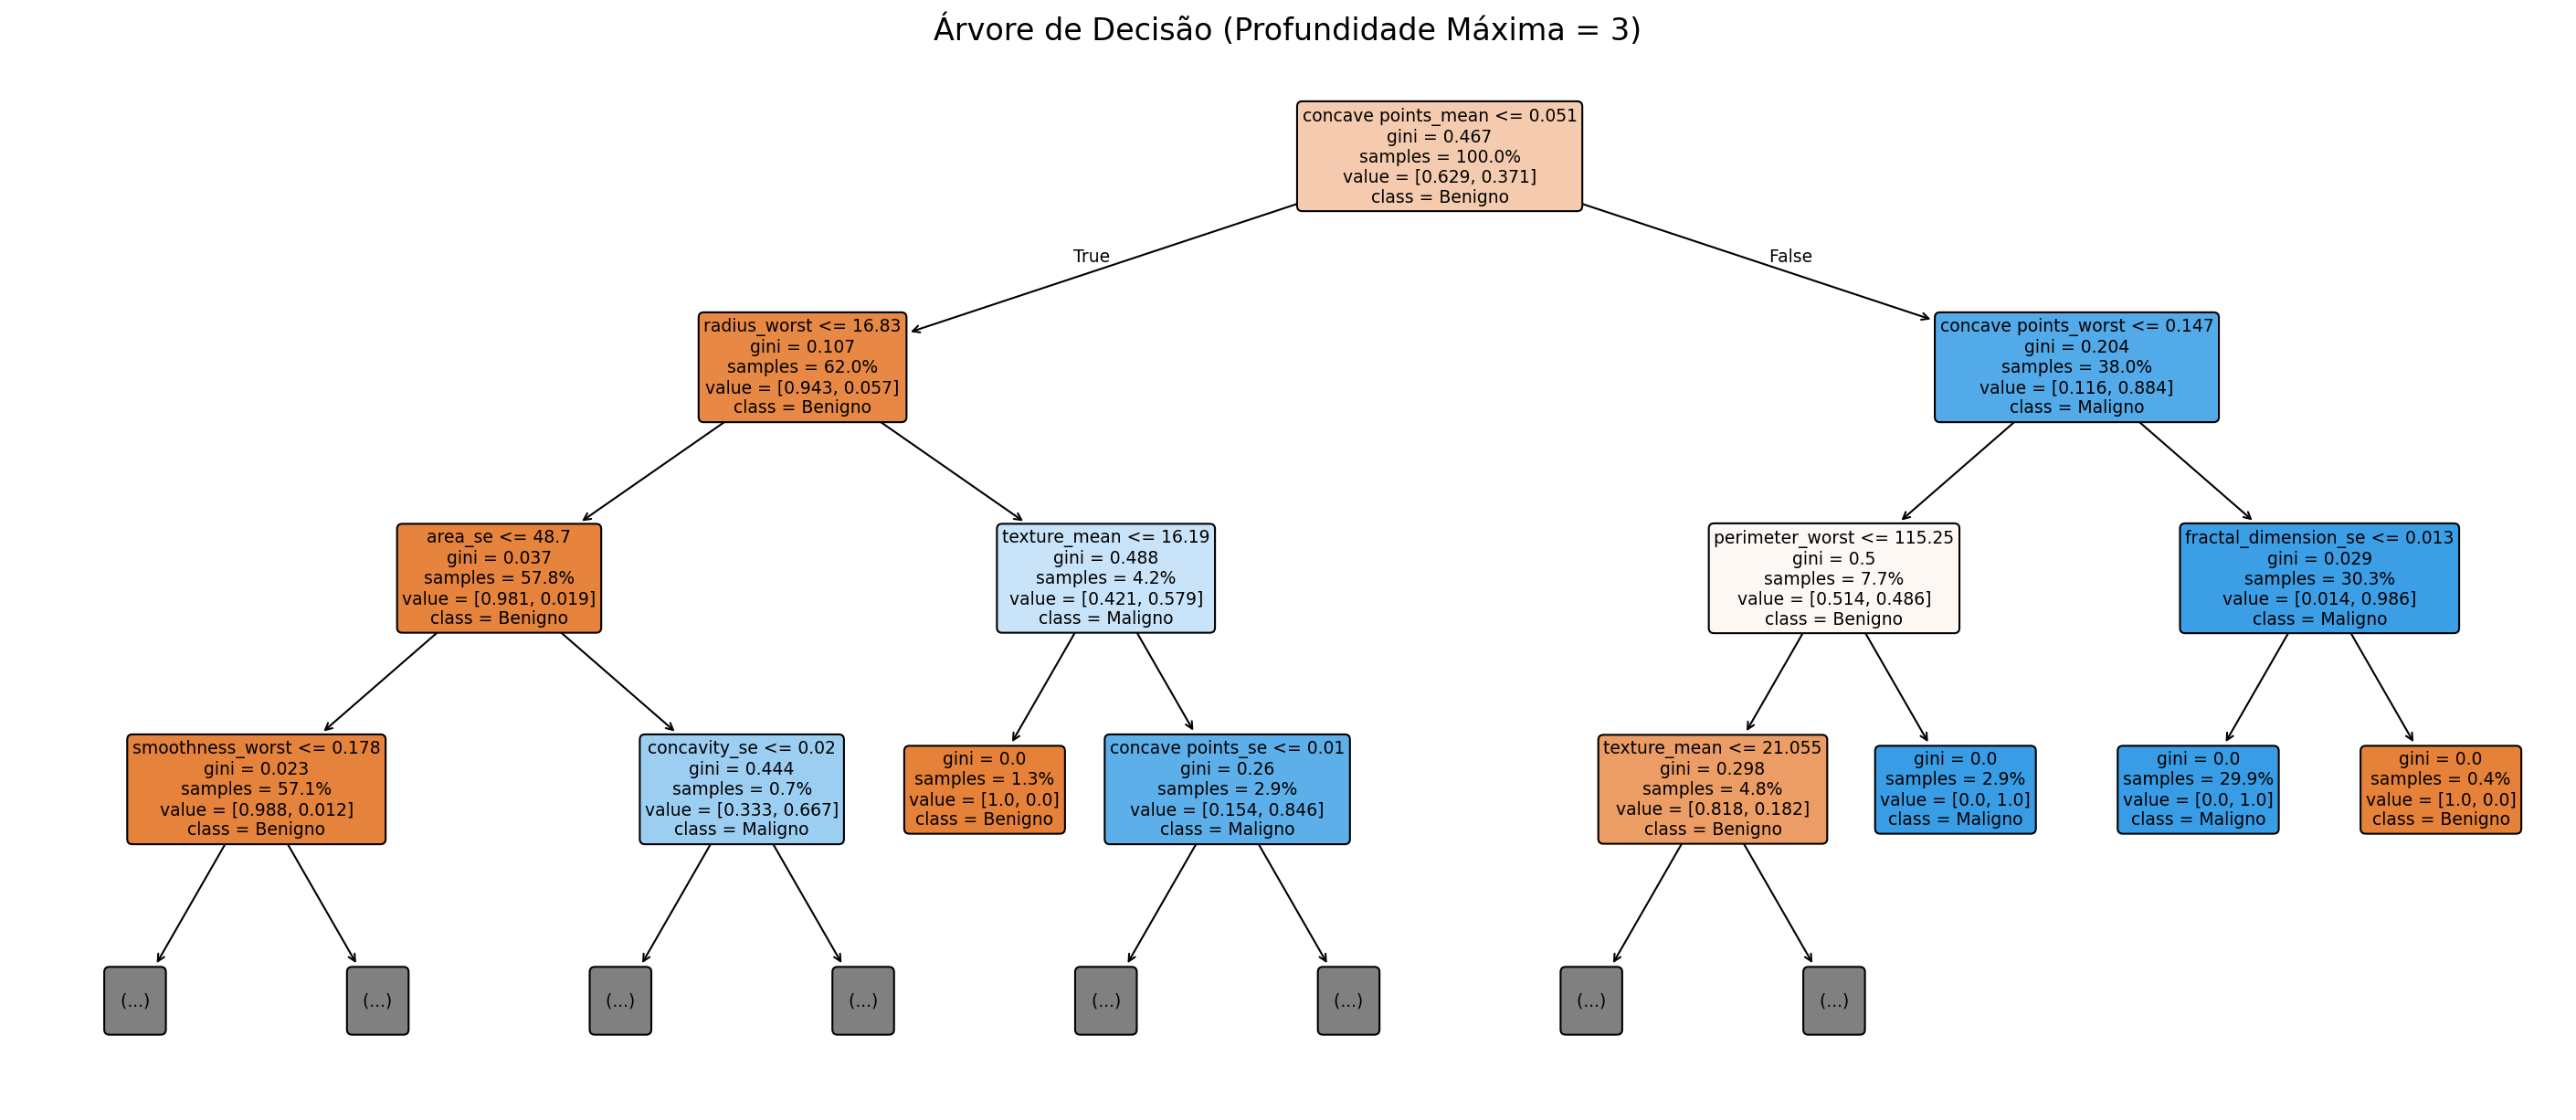

In [175]:
# =====================================
# 9. Decision Tree (Árvore de Decisão)
# =====================================

# Decision Tree
dtree = DecisionTreeClassifier(random_state=42)                                 # Inicializa o modelo de Árvore de Decisão com semente fixa para reprodutibilidade
dtree.fit(X_train, Y_train)                                                     # Treina o classificador utilizando os dados de treino (características e rótulos)
dtree_pred = dtree.predict(X_test)                                              # Gera as previsões para o conjunto de teste (X_test)

# Contagem e Impressão dos Dados Reais
reais = pd.Series(Y_test).value_counts()                                        # Transforma os rótulos reais de teste numa Série e conta as ocorrências de cada classe
print("Totais Reais no Teste:")                                                 # Imprime um cabeçalho informativo no terminal
print(reais.to_string())                                                        # Mostra na consola a contagem real de tumores benignos e malignos

# Contagem e Impressão das Previsões
previstos_dtree = pd.Series(dtree_pred).value_counts()                          # Transforma as previsões da árvore numa Série e conta os totais previstos por classe
print("\nTotais Previstos pela Árvore de Decisão:")                             # Imprime o cabeçalho para os resultados previstos pelo modelo
print(previstos_dtree.to_string())                                              # Mostra na consola a contagem de previsões feitas pela árvore

# Avaliação de Métricas (Recall e Acurácia)
recall_dtree_maligno = recall_score(Y_test, dtree_pred, pos_label='M')          # Calcula a taxa de deteção (Recall) focada nos tumores malignos reais
print(f"\nRecall (Sensibilidade para Malignos) - Árvore: {recall_dtree_maligno:.2%}")  # Imprime o valor do Recall formatado em percentagem
print("\n")                                                                     # Insere uma linha em branco para espaçamento na consola
print(f"Acurácia Árvore de Decisão: {accuracy_score(Y_test, dtree_pred):.2%}")  # Calcula e imprime a percentagem total de acertos do modelo
print("\n")                                                                     # Insere uma nova linha em branco no terminal

# Gráfico ajustado com maior largura para evitar a sobreposição dos nós
plt.figure(figsize=(24, 10), dpi=150)                                           # Cria uma figura ampla (24x10 polegadas) com alta resolução (dpi=150) para o gráfico da árvore
plot_tree(                                                                      # Função do scikit-learn para desenhar esquematicamente a árvore de decisão
    dtree,                                                                      # Passa o modelo de árvore treinado que será desenhado
    max_depth=3,                                                                # Limita visualmente a exibição até 3 níveis de profundidade
    feature_names=X.columns,                                                    # Atribui os nomes reais das colunas/características aos nós de decisão
    class_names=['Benigno', 'Maligno'],                                         # Define os nomes legíveis das classes de diagnóstico
    filled=True,                                                                # Preenche os blocos com cores para indicar a pureza/classe dominante
    rounded=True,                                                               # Arredonda as bordas das caixas/nós do fluxograma
    proportion=True,                                                            # Mostra as proporções de amostras em vez das contagens brutas nos nós
    fontsize=9                                                                  # Define o tamanho da fonte para evitar sobreposições no texto
)
plt.title("Árvore de Decisão (Profundidade Máxima = 3)", fontsize=16)           # Adiciona um título descritivo ao diagrama da árvore
plt.show()                                                                      # Renderiza e exibe o gráfico completo no ecrã


"O algoritmo analisa todos os dados do conjunto de treino (representados aqui pelos 100% de amostras) e calcula estatisticamente que a característica concave points_mean (mede o quão irregular é o contorno das células do tumor) com um limiar de 0.051 é o melhor ponto de corte para iniciar a separação. O índice Gini de 0.467 demonstra que o grupo inicial possui uma mistura considerável entre tumores benignos e malignos (coeficiente estatístico que mede o grau de impureza ou mistura de classes). Com base na distribuição interna de classes (62.9% benignos e 37.1% malignos), o nó define provisoriamente a classe majoritária como Benigno, preparando-se para ramificar os dados e reduzir a impureza nos níveis seguintes."

In [176]:
# =============================================
# Entrada Interativa para a Árvore de Decisão
# =============================================

print("\n--- Simulação com Árvore de Decisão ---")                              # Imprime o cabeçalho descritivo no terminal
print("Dica: Cole todos os 30 valores separados por vírgula de uma só vez.")    # Mostra a instrução para o utilizador colar a linha completa

# Recebe todos os valores numa única linha no terminal
entrada_usuario = input("Informe os 30 valores separados por vírgula:\n> ")     # Aguarda a colagem da string com os 30 valores

# Transforma a string colada numa lista de números (float)
valores_lista = [float(valor.strip()) for valor in entrada_usuario.split(',')]  # Divide o texto por vírgulas, retira espaços e converte cada valor para decimal

# Converte num DataFrame utilizando as mesmas colunas do treino (X.columns)
df_novo_paciente = pd.DataFrame([valores_lista], columns=X.columns)             # Cria um DataFrame do Pandas alinhado com as colunas originais do modelo
print('\n----------------------------------------')

# Realiza a predição utilizando o modelo da Árvore de Decisão
classeRetornada_dt = dtree.predict(df_novo_paciente)                            # Usa o modelo de árvore treinado para prever o diagnóstico
print(f"Classe Retornada: {classeRetornada_dt}")                                # Imprime a classe bruta devolvida pelo modelo (ex: ['B'] ou ['M'])
if classeRetornada_dt[0] == 'B':                                                # Condicional: se a primeira posição for 'B' (Benigno)
    print('Resultado: O paciente apresenta tumor BENIGNO (B).')                 # Mostra a mensagem de tumor benigno
else:                                                                           # Caso contrário (se for 'M')
    print('Resultado: O paciente apresenta tumor MALIGNO (M).')                 # Mostra a mensagem de tumor maligno
print('----------------------------------------')                               # Imprime a linha de fecho do bloco de resultados


--- Simulação com Árvore de Decisão ---
Dica: Cole todos os 30 valores separados por vírgula de uma só vez.
Informe os 30 valores separados por vírgula:
> 17.99, 10.38, 122.80, 1001.0, 0.11840, 0.27760, 0.30010, 0.14710, 0.2419, 0.07871, 1.0950, 0.9053, 8.589, 153.40, 0.006399, 0.049040, 0.05373, 0.015870, 0.03003, 0.006193, 25.38, 17.33, 184.60, 2019.0, 0.1622, 0.6656, 0.7119, 0.26540, 0.4601, 0.11890

----------------------------------------
Classe Retornada: ['M']
Resultado: O paciente apresenta tumor MALIGNO (M).
----------------------------------------


MALIGNO: 17.99, 10.38, 122.80, 1001.0, 0.11840, 0.27760, 0.30010, 0.14710, 0.2419, 0.07871, 1.0950, 0.9053, 8.589, 153.40, 0.006399, 0.049040, 0.05373, 0.015870, 0.03003, 0.006193, 25.38, 17.33, 184.60, 2019.0, 0.1622, 0.6656, 0.7119, 0.26540, 0.4601, 0.11890 BENIGNO: 13.54, 14.36, 87.46, 566.3, 0.09779, 0.08129, 0.06664, 0.04781, 0.1885, 0.05766, 0.2699, 0.7886, 2.058, 23.56, 0.008462, 0.01460, 0.02387, 0.01315, 0.01980, 0.002300, 15.11, 19.26, 99.70, 711.2, 0.1440, 0.1773, 0.2390, 0.12880, 0.2977, 0.07259

Totais Reais no Teste:
diagnosis
B    71
M    43

Totais Previstos pela Random Forest:
B    73
M    41

Recall (Sensibilidade para Malignos) - Random Forest: 93.02%


Acurácia Random Forest: 0.9649




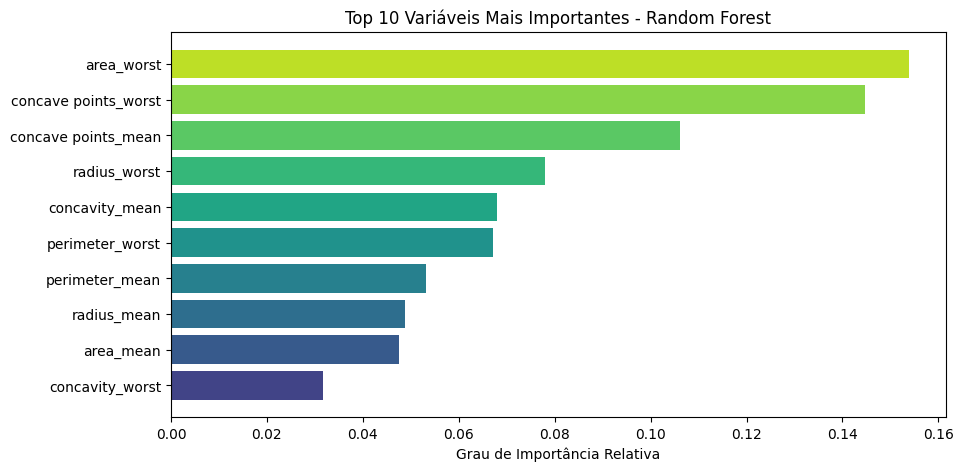

In [177]:
# ======================================
# 10. Random Forest (Floresta Aleatória)
# ======================================
rf = RandomForestClassifier(n_estimators=100, random_state=42)                  # Cria o modelo de Random Forest com 100 árvores e semente fixa para reprodutibilidade
rf.fit(X_train, Y_train)                                                        # Treina o modelo utilizando os dados de treino (características e diagnósticos reais)
rf_pred = rf.predict(X_test)                                                    # Gera as previsões (diagnósticos estimados) para o conjunto de teste oculto

# Análise de totais e Recall para a Random Forest
reais = pd.Series(Y_test).value_counts()                                        # Conta quantos casos reais (Benignos/Malignos) existem no conjunto de teste
print("Totais Reais no Teste:")                                                 # Imprime um cabeçalho informativo no terminal
print(reais.to_string())                                                        # Mostra a contagem real sem formatação extra de "name/dtype"
previstos_rf = pd.Series(rf_pred).value_counts()                                # Conta quantas previsões de cada classe a Random Forest fez
print("\nTotais Previstos pela Random Forest:")                                 # Imprime um cabeçalho para os dados previstos
print(previstos_rf.to_string())                                                 # Mostra a contagem prevista sem formatação extra
recall_rf_maligno = recall_score(Y_test, rf_pred, pos_label='M')                # Calcula o Recall focado na classe 'M' (Maligno) para detetar falsos negativos
print(f"\nRecall (Sensibilidade para Malignos) - Random Forest: {recall_rf_maligno:.2%}")     # Imprime o valor do Recall em formato percentual
print("\n")
print(f"Acurácia Random Forest: {accuracy_score(Y_test, rf_pred):.4f}")         # Calcula e imprime a acurácia geral do modelo com 4 casas decimais
print("\n")

# Importância das Features (Top 10)
importances = rf.feature_importances_                                           # Extrai o grau de importância numérica atribuído pelo modelo a cada variável
indices = np.argsort(importances)[-10:]                                         # Seleciona as 10 mais importantes ordenando os índices de forma crescente e pegando nas últimas 10
plt.figure(figsize=(10, 5))                                                     # Cria uma nova figura de gráfico com dimensões de 10x5 polegadas
plt.title("Top 10 Variáveis Mais Importantes - Random Forest")                  # Define o título principal do gráfico de importância

# Cria uma lista de cores diferentes para cada barra usando uma paleta (ex: 'viridis' ou 'Spectral')
cores = plt.cm.viridis(np.linspace(0.2, 0.9, len(indices)))                     # Gera uma escala de cores suave baseada no mapa 'viridis' para as barras
plt.barh(range(len(indices)), importances[indices], color=cores, align='center')# Desenha o gráfico de barras horizontais com as 10 variáveis
plt.yticks(range(len(indices)), [X.columns[i] for i in indices])                # Substitui os números do eixo Y pelos nomes reais das colunas/variáveis
plt.xlabel("Grau de Importância Relativa")                                      # Define o rótulo do eixo X indicando a importância relativa
plt.show()                                                                      # Renderiza e exibe o gráfico na tela para visualização


In [178]:
# =========================================
# Entrada Interativa para a Random Forest
# =========================================

print("\n--- Simulação com Random Forest ---")                                  # Imprime o cabeçalho descritivo no terminal
print("Dica: Cole todos os 30 valores separados por vírgula de uma só vez.")    # Mostra a instrução para o utilizador colar a linha completa

# Recebe todos os valores numa única linha no terminal
entrada_usuario = input("Informe os 30 valores separados por vírgula:\n> ")     # Aguarda a colagem da string com os 30 valores

# Transforma a string colada numa lista de números (float)
valores_lista = [float(valor.strip()) for valor in entrada_usuario.split(',')]  # Divide o texto por vírgulas, retira espaços e converte cada valor para decimal

# Converte num DataFrame utilizando as mesmas colunas do treino (X.columns)
df_novo_paciente = pd.DataFrame([valores_lista], columns=X.columns)             # Cria um DataFrame do Pandas alinhado com as colunas originais do modelo
print('\n----------------------------------------')

# Realiza a predição utilizando o modelo da Random Forest
classeRetornada_rf = rf.predict(df_novo_paciente)                               # Usa o modelo de Random Forest treinado para prever o diagnóstico
print(f"Classe Retornada: {classeRetornada_rf}")                                # Imprime a classe bruta devolvida pelo modelo (ex: ['B'] ou ['M'])
if classeRetornada_rf[0] == 'B':                                                # Condicional: se a primeira posição for 'B' (Benigno)
    print('Resultado: O paciente apresenta tumor BENIGNO (B).')                 # Mostra a mensagem de tumor benigno
else:                                                                           # Caso contrário (se for 'M')
    print('Resultado: O paciente apresenta tumor MALIGNO (M).')                 # Mostra a mensagem de tumor maligno
print('----------------------------------------')



--- Simulação com Random Forest ---
Dica: Cole todos os 30 valores separados por vírgula de uma só vez.
Informe os 30 valores separados por vírgula:
> 17.99, 10.38, 122.80, 1001.0, 0.11840, 0.27760, 0.30010, 0.14710, 0.2419, 0.07871, 1.0950, 0.9053, 8.589, 153.40, 0.006399, 0.049040, 0.05373, 0.015870, 0.03003, 0.006193, 25.38, 17.33, 184.60, 2019.0, 0.1622, 0.6656, 0.7119, 0.26540, 0.4601, 0.11890

----------------------------------------
Classe Retornada: ['M']
Resultado: O paciente apresenta tumor MALIGNO (M).
----------------------------------------


MALIGNO: 17.99, 10.38, 122.80, 1001.0, 0.11840, 0.27760, 0.30010, 0.14710, 0.2419, 0.07871, 1.0950, 0.9053, 8.589, 153.40, 0.006399, 0.049040, 0.05373, 0.015870, 0.03003, 0.006193, 25.38, 17.33, 184.60, 2019.0, 0.1622, 0.6656, 0.7119, 0.26540, 0.4601, 0.11890 BENIGNO: 13.54, 14.36, 87.46, 566.3, 0.09779, 0.08129, 0.06664, 0.04781, 0.1885, 0.05766, 0.2699, 0.7886, 2.058, 23.56, 0.008462, 0.01460, 0.02387, 0.01315, 0.01980, 0.002300, 15.11, 19.26, 99.70, 711.2, 0.1440, 0.1773, 0.2390, 0.12880, 0.2977, 0.07259

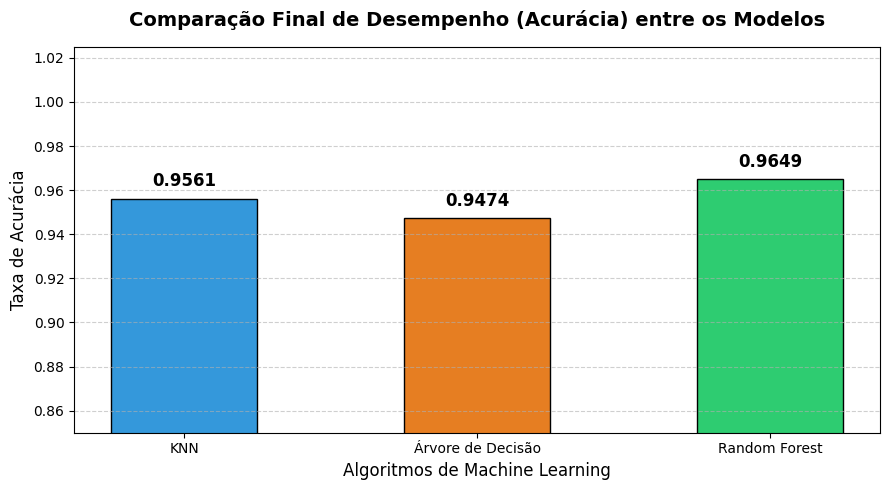

In [179]:
# ==============================================================
# 11. Gráfico Comparativo Final (KNN vs Árvore vs Random Forest)
# ==============================================================
import matplotlib.pyplot as plt                                                 # Importa a biblioteca de gráficos matplotlib para desenhar a visualização
import numpy as np                                                              # Importa a biblioteca numpy para operações numéricas e manipulação de arrays

# Recolher os nomes dos modelos e as respetivas acurácias calculadas anteriormente
nomes_modelos = ['KNN', 'Árvore de Decisão', 'Random Forest']                   # Define a lista com os nomes dos três modelos a comparar no eixo X
acuracias = [                                                                   # Cria uma lista recolhendo as pontuações de acurácia de cada modelo no teste
    accuracy_score(Y_test, knn_pred),                                           # Calcula a acurácia do modelo KNN comparando o real com o previsto
    accuracy_score(Y_test, dtree_pred),                                         # Calcula a acurácia da Árvore de Decisão
    accuracy_score(Y_test, rf_pred)                                             # Calcula a acurácia da Random Forest
]

# Criar a figura com um design limpo e profissional
plt.figure(figsize=(9, 5))                                                      # Define o tamanho da janela do gráfico em polegadas (largura 9, altura 5)

# Cores distintas e elegantes para cada modelo
cores = ['#3498db', '#e67e22', '#2ecc71']                                       # Atribui códigos de cores em hexadecimal para diferenciar as barras visualmente
barras = plt.bar(nomes_modelos, acuracias, color=cores, width=0.5, edgecolor='black', linewidth=1)    # Desenha o gráfico de barras verticais com bordas pretas

# Adicionar o valor exato da acurácia em cima de cada barra (ótimo para visualização em aula)
for barra in barras:                                                            # Inicia um ciclo para percorrer cada barra desenhada no gráfico
    altura = barra.get_height()                                                 # Obtém a altura da barra atual, que corresponde exatamente ao valor da acurácia
    plt.annotate(f'{altura:.4f}',                                               # Cria um texto com a acurácia formatada com 4 casas decimais
                 xy=(barra.get_x() + barra.get_width() / 2, altura),            # Define a posição X (centro da barra) e Y (topo da barra) para o texto
                 xytext=(0, 6),  # Deslocamento vertical em pontos              # Afasta o texto levemente 6 pontos para cima do topo da barra
                 textcoords="offset points",                                    # Especifica que o deslocamento é baseado em pontos de coordenadas relativas
                 ha='center', va='bottom', fontsize=12, fontweight='bold')      # Alinha o texto ao centro e em negrito para facilitar a leitura

# Configurações visuais do gráfico
plt.ylim(0.85, 1.025)                                                           # Ajusta o zoom para evidenciar pequenas variações de desempenho # Define os limites mínimo e máximo do eixo Y para dar zoom nas diferenças
plt.title("Comparação Final de Desempenho (Acurácia) entre os Modelos", fontsize=14, fontweight='bold', pad=15) # Define o título principal do gráfico
plt.ylabel("Taxa de Acurácia", fontsize=12)                                     # Atribui o rótulo descritivo ao eixo Y
plt.xlabel("Algoritmos de Machine Learning", fontsize=12)                       # Atribui o rótulo descritivo ao eixo X
plt.grid(axis='y', linestyle='--', alpha=0.6)                                   # Adiciona linhas de grelha horizontais tracejadas para orientar a leitura visual

# Mostrar o gráfico final
plt.tight_layout()                                                              # Ajusta automaticamente os espaçamentos para evitar cortes nos elementos
plt.show()                                                                      # Renderiza e exibe o gráfico final na tela para a turma


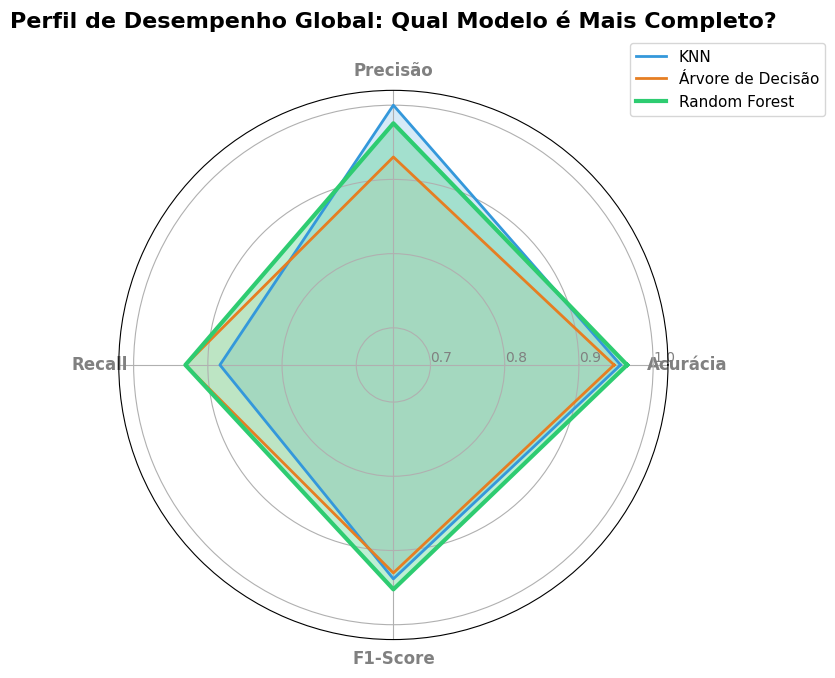


--- RESUMO DOS RESULTADOS ---
KNN          -> Acurácia: 0.956 | Precisão: 1.000 | Recall: 0.884 | F1: 0.938
Árvore       -> Acurácia: 0.947 | Precisão: 0.930 | Recall: 0.930 | F1: 0.930
Random Forest-> Acurácia: 0.965 | Precisão: 0.976 | Recall: 0.930 | F1: 0.952

--- DEFINIÇÕES DAS MÉTRICAS ---
Acurácia: Percentagem total de diagnósticos corretos (tanto saudáveis quanto doentes) sobre o total de pacientes.
Precisão: Taxa de acerto quando o modelo diz que é câncer (minimiza os falsos alarmes em pacientes saudáveis).
Recall: Taxa de deteção de todos os cânceres reais (minimiza os falsos negativos, evitando deixar doentes escapar).
F1-Score: Média harmónica que mede o equilíbrio perfeito entre a precisão e o recall.


In [180]:
# =========================================
# 12. Gráfico de Radar: Comparação Global
# =========================================
import matplotlib.pyplot as plt                                                 # Importa a biblioteca para criar gráficos
import numpy as np                                                              # Importa o NumPy para cálculos numéricos e arrays
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score  # Importa as métricas de avaliação

# Calcular as métricas (garantindo que temos os valores atualizados)
def calcular_metricas(y_true, y_pred):                                          # Define uma função para calcular todas as métricas de uma vez
    acc = accuracy_score(y_true, y_pred)                                        # Calcula a acurácia global do modelo
    prec = precision_score(y_true, y_pred, pos_label='M', zero_division=0)      # Calcula a precisão para a classe Maligna
    rec = recall_score(y_true, y_pred, pos_label='M', zero_division=0)          # Calcula o recall para a classe Maligna
    f1 = f1_score(y_true, y_pred, pos_label='M', zero_division=0)               # Calcula o F1-Score combinando ambos
    return [acc, prec, rec, f1]                                                 # Retorna a lista com as quatro métricas

scores_knn = calcular_metricas(Y_test, knn_pred)                                # Calcula as métricas para o KNN
scores_dt = calcular_metricas(Y_test, dtree_pred)                               # Calcula as métricas para a Árvore de Decisão
scores_rf = calcular_metricas(Y_test, rf_pred)                                  # Calcula as métricas para o Random Forest

# Configuração do Gráfico de Radar
atributos = ['Acurácia', 'Precisão', 'Recall', 'F1-Score']                      # Define os eixos do gráfico de radar
num_atributos = len(atributos)                                                  # Conta quantos atributos/eixos existem

# Calcular os ângulos para cada atributo no círculo
angulos = np.linspace(0, 2 * np.pi, num_atributos, endpoint=False).tolist()     # Divide o círculo em partes iguais para cada métrica

# O gráfico de radar precisa "fechar o círculo", então repetimos o primeiro valor
scores_knn += scores_knn[:1]                                                    # Repete a primeira métrica do KNN no fim para fechar o polígono
scores_dt += scores_dt[:1]                                                      # Repete a primeira métrica da Árvore no fim
scores_rf += scores_rf[:1]                                                      # Repete a primeira métrica da Random Forest no fim
angulos += angulos[:1]                                                          # Repete o primeiro ângulo para fechar o circuito do radar

# Plotagem
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))             # Cria uma figura com eixo polar (circular)

# Ajustar os rótulos dos eixos (as métricas)
plt.xticks(angulos[:-1], atributos, color='grey', size=12, fontweight='bold')   # Define os nomes de cada ponta do radar

# Ajustar os rótulos das linhas de grade (as pontuações)
ax.set_rlabel_position(0)                                                       # Posiciona os rótulos radiais no topo
plt.yticks([0.7, 0.8, 0.9, 1.0], ["0.7", "0.8", "0.9", "1.0"], color="grey", size=10)  # Define as linhas concêntricas de valor
plt.ylim(0.65, 1.02)                                                            # Define o limite do zoom (de 0.65 a 1.02)

# Desenhar e preencher as áreas de cada modelo
# KNN (Azul)
ax.plot(angulos, scores_knn, linewidth=2, linestyle='solid', label="KNN", color='#3498db')  # Desenha a linha do KNN
ax.fill(angulos, scores_knn, color='#3498db', alpha=0.2)                                   # Preenche a área do KNN com transparência

# Árvore de Decisão (Laranja)
ax.plot(angulos, scores_dt, linewidth=2, linestyle='solid', label="Árvore de Decisão", color='#e67e22')  # Desenha a linha da Árvore
ax.fill(angulos, scores_dt, color='#e67e22', alpha=0.1)                                                  # Preenche a área da Árvore

# Random Forest (Verde) - O Vencedor, com linha mais grossa
ax.plot(angulos, scores_rf, linewidth=3, linestyle='solid', label="Random Forest", color='#2ecc71')  # Desenha a linha mais grossa da Random Forest
ax.fill(angulos, scores_rf, color='#2ecc71', alpha=0.3)                                              # Preenche a área de destaque da Random Forest

# Finalização Estética
plt.title('Perfil de Desempenho Global: Qual Modelo é Mais Completo?', size=16, fontweight='bold', y=1.1)  # Adiciona o título principal
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=11)                                     # Posiciona a legenda fora do gráfico

plt.tight_layout()                                                              # Ajusta o layout para evitar cortes
plt.show()                                                                      # Exibe o gráfico gerado


# Impressão dos resultados e definições logo abaixo do gráfico
print("\n--- RESUMO DOS RESULTADOS ---")
print(f"KNN          -> Acurácia: {scores_knn[0]:.3f} | Precisão: {scores_knn[1]:.3f} | Recall: {scores_knn[2]:.3f} | F1: {scores_knn[3]:.3f}")  # Imprime scores do KNN
print(f"Árvore       -> Acurácia: {scores_dt[0]:.3f} | Precisão: {scores_dt[1]:.3f} | Recall: {scores_dt[2]:.3f} | F1: {scores_dt[3]:.3f}")    # Imprime scores da Árvore
print(f"Random Forest-> Acurácia: {scores_rf[0]:.3f} | Precisão: {scores_rf[1]:.3f} | Recall: {scores_rf[2]:.3f} | F1: {scores_rf[3]:.3f}")    # Imprime scores da Random Forest

print("\n--- DEFINIÇÕES DAS MÉTRICAS ---")
print("Acurácia: Percentagem total de diagnósticos corretos (tanto saudáveis quanto doentes) sobre o total de pacientes.")
print("Precisão: Taxa de acerto quando o modelo diz que é câncer (minimiza os falsos alarmes em pacientes saudáveis).")
print("Recall: Taxa de deteção de todos os cânceres reais (minimiza os falsos negativos, evitando deixar doentes escapar).")
print("F1-Score: Média harmónica que mede o equilíbrio perfeito entre a precisão e o recall.")